# Landscape Modeling

Brendan Harmon  
2026-09-06

<figure>
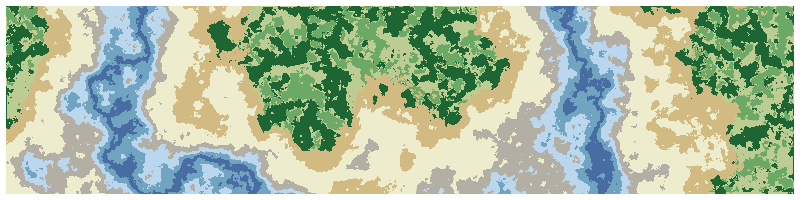
<figcaption aria-hidden="true">Landscape modeling</figcaption>
</figure>

Learn how to generate fractal terrain, derive landcover from the
terrain, and draw landcover with the raster digitizer.

| Value | Category                      |
|-------|-------------------------------|
| 11    | Open Water                    |
| 21    | Developed, Open Space         |
| 22    | Developed, Low Intensity      |
| 23    | Developed, Medium Intensity   |
| 24    | Developed, High Intensity     |
| 31    | Barren Land                   |
| 41    | Deciduous Forest              |
| 42    | Evergreen Forest              |
| 43    | Mixed Forest                  |
| 52    | Shrub/Scrub                   |
| 71    | Grassland/Herbaceuous         |
| 81    | Pasture/Hay                   |
| 82    | Cultivated Crops              |
| 90    | Woody Wetlands                |
| 95    | Emergent Herbaceuous Wetlands |

Landcover categories

## Setup

Start a GRASS session in a project with a Cartesian coordinate system.

In [1]:
# Import modules
import io
import sys
import subprocess
from pathlib import Path
from contextlib import suppress

# Find GRASS Python packages
sys.path.append(
  subprocess.check_output(
    ["grass", "--config", "python_path"],
    text=True
    ).strip()
  )

# Import GRASS packages
import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

# Create and initialize GRASS project
try:
    gj.init("cartesian")
except ValueError:
    with suppress(ValueError):
        gs.create_project("cartesian")
        gj.init("cartesian")
tools = Tools(overwrite=True)
tools.g_proj(format="plain", flags="p").text

## Set computational region

[g.region](https://grass.osgeo.org/grass-stable/manuals/g.region.html)

In [2]:
# Set region
tools.g_region(n=200, s=0, e=800, w=0, res=1)

## Generate fractal terrain

[r.surf.fractal](https://grass.osgeo.org/grass-stable/manuals/r.surf.fractal.html)

In [3]:
# Generate fractal terrain
tools.r_surf_fractal(output="fractal", dimension=2.25, seed=24)

# Model river valleys
tools.r_mapcalc(expression="terrain = abs(fractal) / 10")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="terrain")
m.d_legend(raster="terrain", at=(5, 95, 1, 3))
m.show()
m.save("images/landscape-01.webp")

# Print elevation range
info = tools.r_info(map="terrain", flags="r", format="json")
print(f"Mininum elevation: {info["min"]:05.2f}")
print(f"Maximum elevation: {info["max"]:05.2f}")

<figure>
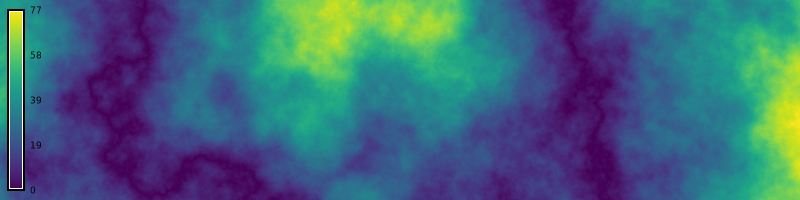
<figcaption aria-hidden="true">Fractal terrain</figcaption>
</figure>

## Model rivers

[r.mapcalc](https://grass.osgeo.org/grass-stable/manuals/r.mapcalc.html)
[r.colors](https://grass.osgeo.org/grass-stable/manuals/r.colors.html)

In [4]:
# Derive river from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain <= 2, 11, 31)")

# Derive wetlands from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 2 && terrain <= 6, 95, landcover)")

# Derive woody wetlands from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 6 && terrain < 10, 90, landcover)")

# Set landcover colors
tools.r_colors(map="landcover", color="nlcd")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.show()
m.save("images/landscape-02.webp")

<figure>
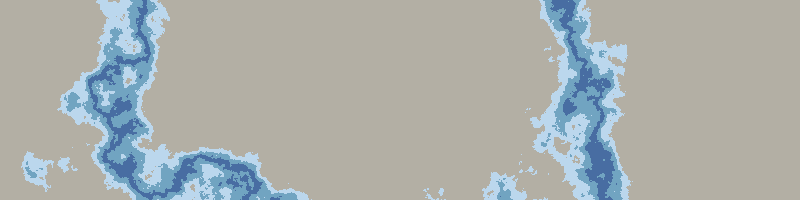
<figcaption aria-hidden="true">River valleys</figcaption>
</figure>

## Classify landforms

[r.grow](https://grass.osgeo.org/grass-stable/manuals/r.grow.html)
[r.geomorphon](https://grass.osgeo.org/grass-stable/manuals/r.geomorphon.html)

In [5]:
# Classify landforms
tools.r_grow(input="terrain", output="elevation", radius=25)
tools.r_geomorphon(elevation="elevation", forms="landforms", search=25, skip=5, flat=1, dist=0)

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landforms")
m.show()
m.save("images/landscape-03.webp")

<figure>
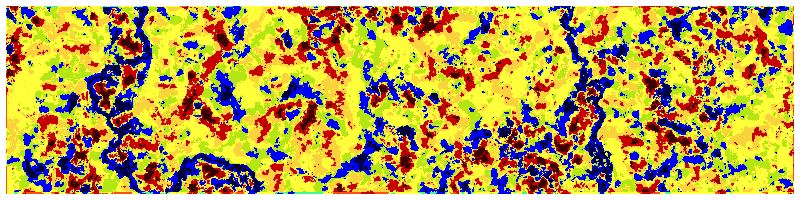
<figcaption aria-hidden="true">Landforms</figcaption>
</figure>

## Model uplands

[r.mapcalc](https://grass.osgeo.org/grass-stable/manuals/r.mapcalc.html)

In [6]:
# Derive grass from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 15, 71, landcover)")

# Derive shrubs from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 30, 52, landcover)")

# Derive shrubs from landforms
tools.r_mapcalc(expression = "landcover = if(landcover == 71 & terrain > 25 & landforms < 7, 52, landcover)")

# Derive deciduous forest from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 35, 41, landcover)")

# Derive mixed forest from landforms
tools.r_mapcalc(expression = "landcover = if(terrain > 35 && landforms == 6, 43, landcover)")

# Derive evergreen forest from landforms
tools.r_mapcalc(expression = "landcover = if(terrain > 35 && landforms < 6, 42, landcover)")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.show()
m.save("images/landscape-04.webp")

<figure>
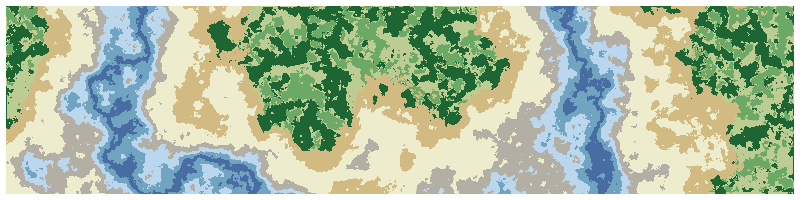
<figcaption aria-hidden="true">Uplands</figcaption>
</figure>

## Model wetlands

[r.fill_dir](https://grass.osgeo.org/grass-stable/manuals/r.fill.dir.html)
[r.mapcalc](https://grass.osgeo.org/grass-stable/manuals/r.mapcalc.html)

In [7]:
# Find depressions
tools.r_fill_dir(input="terrain", output="fill", areas="areas", direction="direction")

# Calculate depth
tools.r_mapcalc(expression = "ponds = terrain - fill")

# Derive ponds from depressions
tools.r_mapcalc(expression = "landcover = if(terrain > 10 && terrain < 30 && ponds < -0.5, 11, landcover)")

# Derive wetlands from depressions
tools.r_mapcalc(expression = "landcover = if(terrain > 10 && terrain < 30 && ponds < -0.5  && ponds > -1.0, 95, landcover)")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.show()
m.save("images/landscape-05.webp")

<figure>
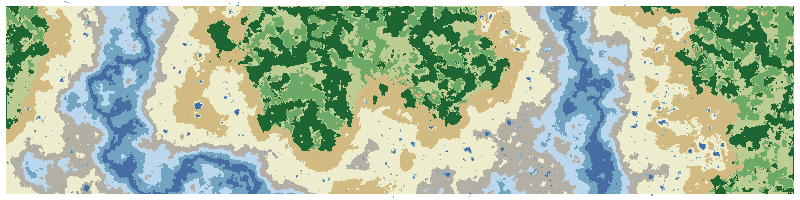
<figcaption aria-hidden="true">Uplands</figcaption>
</figure>

## Define landcover categories

In [8]:
categories = """\
11|Open Water
12|Perennial Ice/Snow
21|Developed, Open Space
22|Developed, Low Intensity
23|Developed, Medium Intensity
24|Developed, High Intensity
31|Barren Land
41|Deciduous Forest
42|Evergreen Forest
43|Mixed Forest
51|Dwarf Scrub
52|Shrub/Scrub
71|Grassland/Herbaceuous
72|Sedge/Herbaceous
73|Lichens
74|Moss
81|Pasture/Hay
82|Cultivated Crops
90|Woody Wetlands
95|Emergent Herbaceuous Wetlands
"""

[r.category](https://grass.osgeo.org/grass-stable/manuals/r.category.html)

In [9]:
# Set landcover categories
tools.r_category(map="landcover", separator="pipe", rules=io.StringIO(categories))

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.d_legend(raster="landcover", at=(5, 95, 1, 3), use=(11,31,41,42,43,52,71,90,95))
m.show()
m.save("images/landscape-06.webp")

<figure>
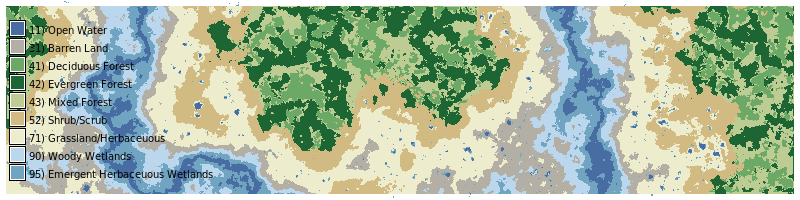
<figcaption aria-hidden="true">Uplands</figcaption>
</figure>

## Draw landcover

[g.gui.rdigit](https://grass.osgeo.org/grass-stable/manuals/g.gui.rdigit.html)

In [10]:
# Generate fractal terrain
# tools.r_surf_fractal(output="fractal", dimension=2.25, seed=27)
tools.r_surf_fractal(output="fractal", dimension=2.01, seed=27)

# Model river valleys
tools.r_mapcalc(expression="terrain = abs(fractal) / 10")

# Derive river from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain <= 2, 11, 31)")

# Derive wetlands from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 2 && terrain <= 6, 95, landcover)")

# Derive woody wetlands from elevation gradient
tools.r_mapcalc(expression = "landcover = if(terrain > 6 && terrain < 10, 90, landcover)")

# Set landcover colors
tools.r_colors(map="landcover", color="nlcd")

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.show()
m.save("images/landscape-07.webp")

<figure>
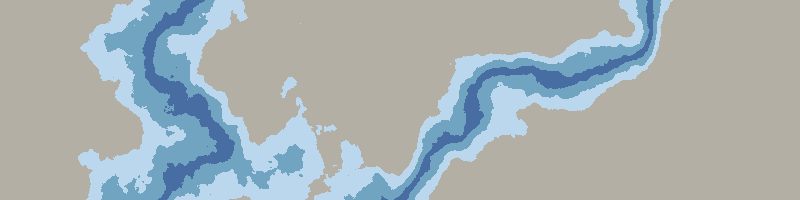
<figcaption aria-hidden="true">Uplands</figcaption>
</figure>

[g.gui.rdigit](https://grass.osgeo.org/grass-stable/manuals/g.gui.rdigit.html)

In [11]:
# Digitize
tools.g_gui_rdigit(edit="landcover", type="CELL")

# Set landcover categories
tools.r_category(map="landcover", separator="pipe", rules=io.StringIO(categories))

# Visualize
m = gj.Map(width=800)
m.d_rast(map="landcover")
m.d_legend(raster="landcover", at=(5, 95, 1, 3), use=(11,31,41,42,43,52,71,90,95))
m.show()
m.save("images/landscape-08.webp")

<figure>
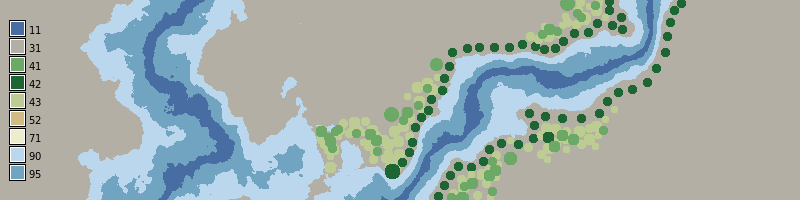
<figcaption aria-hidden="true">Uplands</figcaption>
</figure>